# Cruce | Tortilla, salario mínimo y maíz

## 1 | Pregunta y decisiones

**¿Cuánto del salario mínimo se come la tortilla?**

La libreta cruza el salario mínimo (CONASAMI), el precio de la tortilla (PROFECO), el consumo de los hogares (ENIGH), el maíz blanco mayorista (SNIIM) y el rendimiento de Gruma. La métrica central es el costo diario de la tortilla que compra un hogar promedio, como porcentaje del salario mínimo diario.

Decisiones:

- Ventana: precios de tortilla desde enero de 2015; ENIGH desde 2014. Los años 2014 y 2026 solo se usan donde hay datos.
- Los meses sin precio PROFECO no se interpolan: se omiten y las gráficas muestran el hueco.
- El cruce con maíz y con Gruma describe asociación, no causalidad.
- Las funciones de cálculo están en `rendimiento_bachoco/features.py`.

## 2 | Fuentes y supuestos

| Fuente | Variable usada | Unidad |
| --- | --- | --- |
| CONASAMI | Salario mínimo diario, `general` y `zlfn` (Zona Libre de la Frontera Norte, desde 2019) | MXN/día |
| PROFECO | Mediana nacional del precio de la tortilla de maíz en tortillería (mediana de medianas estatales) | MXN/kg |
| ENIGH | Kilos y gasto diarios de tortilla por hogar (compra monetaria), bienal 2014–2024 | kg/día, MXN/día |
| SNIIM | Maíz blanco mayorista, promedio de cinco mercados | MXN/kg |
| Yahoo Finance | Rendimiento mensual de Gruma (`GRUMAB.MX`) | fracción |

Supuestos:

1. **Consumo mensual.** El kg diario por hogar se interpola linealmente entre levantamientos (anclados en octubre) y se mantiene constante antes de 2014 y después de 2024.
2. **Costo.** `costo = precio_kg × kg_día_hogar`; `pct_salario = costo / salario_diario × 100`. Compara el gasto del hogar con un solo salario mínimo; no es el ingreso del hogar.
3. **Jornada** de 8 horas: `minutos_por_kg = precio / (salario / 8) × 60`.
4. **Precios corrientes**, sin deflactar: el salario y la tortilla se comparan en la misma moneda de cada mes.
5. **Promedio anual** con los meses que tienen precio (entre 3 y 10 por año); `n_meses` lo indica.
6. **ZLFN** usa el mismo precio y consumo nacionales con el salario de la frontera: es una cota inferior de la carga en esa zona, no una medición local.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from rendimiento_bachoco.features import (
    consumo_hogar_mensual,
    pct_salario_por_decil,
    pct_salario_por_entidad,
    tortilla_salario_anual,
    tortilla_salario_mensual,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)

raiz = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "processed" / "precio_tortilla_mensual.csv").is_file()
)
PROC, FIGS = raiz / "data" / "processed", raiz / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

C_GEN, C_ZLFN, C_MAIZ, C_GRUMA, C_GRIS = "#3b68a6", "#d98324", "#247f78", "#8a4f9e", "#8c8c8c"
CALENDARIO = pd.date_range("2013-01-01", "2025-12-01", freq="MS")


def guardar(fig, nombre):
    fig.savefig(FIGS / f"tortilla_cruce_{nombre}.png", dpi=150, bbox_inches="tight")


salario = pd.read_csv(PROC / "salario_minimo_mensual.csv", parse_dates=["fecha"])
precio = pd.read_csv(PROC / "precio_tortilla_mensual.csv", parse_dates=["fecha"])
enigh = pd.read_csv(PROC / "enigh_tortilla_hogar.csv", dtype={"clave_nivel": str})
sniim = pd.read_csv(PROC / "sniim_maiz_blanco_mensual.csv", parse_dates=["fecha"])
rend = pd.read_parquet(raiz / "data" / "interim" / "rendimiento_mensual.parquet")

pd.DataFrame({
    "filas": [len(salario), len(precio), len(enigh), len(sniim), len(rend)],
    "desde": [salario.fecha.min(), precio.fecha.min(), enigh.anio.min(), sniim.fecha.min(), rend.index.min()],
    "hasta": [salario.fecha.max(), precio.fecha.max(), enigh.anio.max(), sniim.fecha.max(), rend.index.max()],
}, index=["salario", "precio tortilla", "ENIGH", "SNIIM", "rendimiento"])

2026-11-12 21:47:01.042 | INFO     | rendimiento_bachoco.config:<module>:15 - La ruta de PROJ_ROOT es: /Users/manuel_gortarez/Projects/Rendimiento_Bursatil_Sector_Agropecuario


,filas,desde,hasta
salario,264,2013-01-01 00:00:00,2026-12-01 00:00:00
precio tortilla,5337,2015-01-01 00:00:00,2026-03-01 00:00:00
ENIGH,258,2014,2024
SNIIM,960,2013-01-01 00:00:00,2025-12-01 00:00:00
rendimiento,321,2000-01-31 00:00:00,2026-09-30 00:00:00


## 3 | Porcentaje del salario mínimo que se come la tortilla

Se calcula para el salario general y para la ZLFN. Las celdas guardan los resultados en `data/processed/`.

In [2]:
consumo = consumo_hogar_mensual(enigh)
mensual = {a: tortilla_salario_mensual(salario, precio, consumo, area=a) for a in ["general", "zlfn"]}
anual = {a: tortilla_salario_anual(salario, precio, consumo, enigh, area=a) for a in ["general", "zlfn"]}

pd.concat(mensual.values(), ignore_index=True).to_csv(PROC / "tortilla_salario_mensual.csv", index=False)
pd.concat(anual.values(), ignore_index=True).to_csv(PROC / "tortilla_salario_anual.csv", index=False)

G = anual["general"].set_index("anio")
Z = anual["zlfn"].set_index("anio")
M = mensual["general"].set_index("fecha")
MZ = mensual["zlfn"].set_index("fecha")

tabla = pd.DataFrame({
    "meses con precio": G.n_meses,
    "precio MXN/kg": G.precio_kg,
    "salario general": G.salario_diario,
    "% salario general": G.pct_salario,
    "% salario ZLFN": Z.pct_salario,
    "% ENIGH directo general": G.pct_salario_enigh,
    "% ENIGH directo ZLFN": Z.pct_salario_enigh,
    "minutos por kg": G.minutos_trabajo_por_kg,
})
tabla.round(2)

,meses con precio,precio MXN/kg,salario general,% salario general,% salario ZLFN,% ENIGH directo general,% ENIGH directo ZLFN,minutos por kg
anio,,,,,,,,
2014,NaN,NaN,NaN,NaN,NaN,10.09,NaN,NaN
2015,8.0,13.41,67.59,10.62,NaN,NaN,NaN,95.20
2016,7.0,13.64,73.04,9.74,NaN,8.84,NaN,89.66
2017,8.0,14.76,80.04,9.48,NaN,NaN,NaN,88.55
2018,8.0,15.00,88.36,8.72,NaN,8.34,NaN,81.48
2019,9.0,15.33,102.68,7.72,4.49,NaN,NaN,71.68
2020,9.0,16.08,123.22,6.82,4.53,6.59,4.38,62.65
2021,10.0,17.91,141.70,6.48,4.30,NaN,NaN,60.68
2022,3.0,19.67,172.87,5.67,3.77,5.97,3.97,54.61


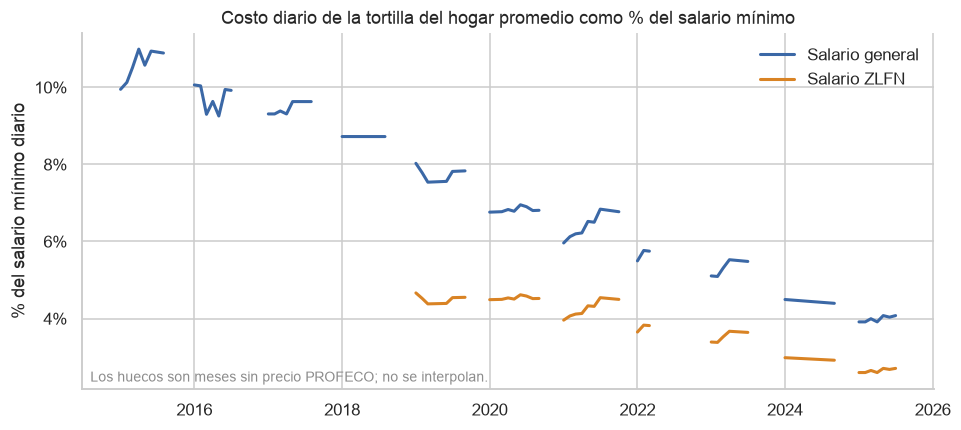

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for serie, color, etiqueta in [(M, C_GEN, "Salario general"), (MZ, C_ZLFN, "Salario ZLFN")]:
    s = serie["pct_salario"].reindex(pd.date_range("2015-01-01", "2025-12-01", freq="MS"))
    ax.plot(s.index, s, color=color, lw=2, label=etiqueta)
ax.set_ylabel("% del salario mínimo diario")
ax.set_title("Costo diario de la tortilla del hogar promedio como % del salario mínimo")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False)
ax.text(0.01, 0.02, "Los huecos son meses sin precio PROFECO; no se interpolan.", transform=ax.transAxes, fontsize=9, color=C_GRIS)
guardar(fig, "pct_salario_mensual")
plt.show()

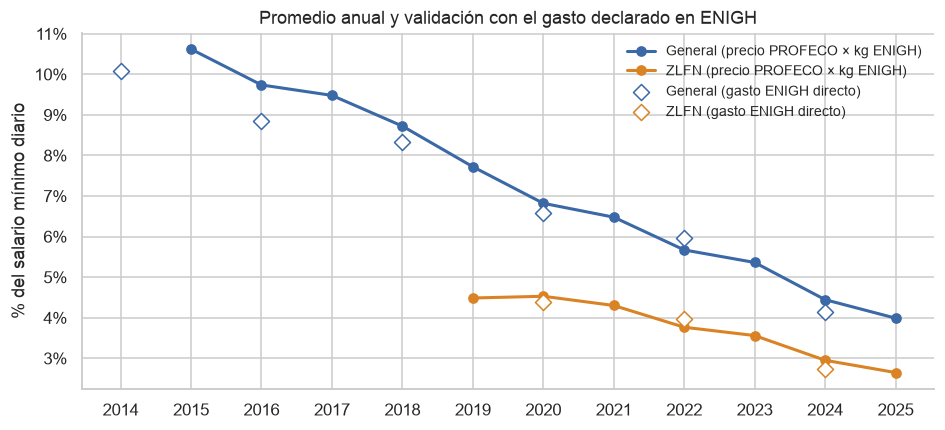

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(G.index, G.pct_salario, color=C_GEN, lw=2, marker="o", label="General (precio PROFECO × kg ENIGH)")
ax.plot(Z.index, Z.pct_salario, color=C_ZLFN, lw=2, marker="o", label="ZLFN (precio PROFECO × kg ENIGH)")
ax.scatter(G.index, G.pct_salario_enigh, color=C_GEN, marker="D", s=55, facecolor="white", zorder=3, label="General (gasto ENIGH directo)")
ax.scatter(Z.index, Z.pct_salario_enigh, color=C_ZLFN, marker="D", s=55, facecolor="white", zorder=3, label="ZLFN (gasto ENIGH directo)")
ax.set_ylabel("% del salario mínimo diario")
ax.set_xticks(range(2014, 2026))
ax.set_title("Promedio anual y validación con el gasto declarado en ENIGH")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, fontsize=9)
guardar(fig, "pct_salario_anual")
plt.show()

In [5]:
val = pd.DataFrame({
    "pct con precio PROFECO": G.pct_salario,
    "pct ENIGH directo": G.pct_salario_enigh,
}).dropna()
val["diferencia (pp)"] = val["pct con precio PROFECO"] - val["pct ENIGH directo"]
display(val.round(2))
display(Markdown(
    f"En los años de levantamiento con precio, la medición con precio PROFECO difiere de la ENIGH directa entre "
    f"{val['diferencia (pp)'].min():.2f} y {val['diferencia (pp)'].max():.2f} puntos porcentuales "
    f"(mediana {val['diferencia (pp)'].median():.2f}). "
    f"Ambas series bajan en el mismo sentido."
))

,pct con precio PROFECO,pct ENIGH directo,diferencia (pp)
anio,,,
2016,9.74,8.84,0.90
2018,8.72,8.34,0.39
2020,6.82,6.59,0.23
2022,5.67,5.97,-0.30
2024,4.44,4.14,0.31


En los años de levantamiento con precio, la medición con precio PROFECO difiere de la ENIGH directa entre -0.30 y 0.90 puntos porcentuales (mediana 0.31). Ambas series bajan en el mismo sentido.

**Lectura.** El porcentaje depende de dos movimientos opuestos: la tortilla sube de precio, pero el salario mínimo sube más rápido y el hogar compra menos kilos. La validación con el gasto declarado en ENIGH permite revisar que el resultado no depende de usar precios de otra fuente.

## 4 | Minutos de trabajo por kilo y kilos que compra un salario

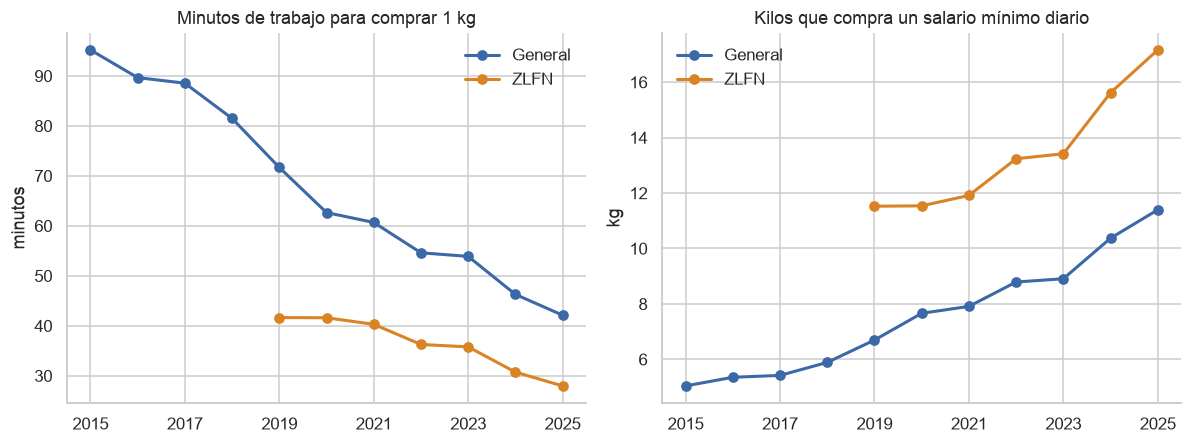

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for tabla_a, color, etiqueta in [(G, C_GEN, "General"), (Z, C_ZLFN, "ZLFN")]:
    axes[0].plot(tabla_a.index, tabla_a.minutos_trabajo_por_kg, color=color, lw=2, marker="o", label=etiqueta)
    axes[1].plot(tabla_a.index, tabla_a.kg_por_salario, color=color, lw=2, marker="o", label=etiqueta)
axes[0].set_title("Minutos de trabajo para comprar 1 kg")
axes[0].set_ylabel("minutos")
axes[1].set_title("Kilos que compra un salario mínimo diario")
axes[1].set_ylabel("kg")
for ax in axes:
    ax.set_xticks(range(2015, 2026, 2))
    ax.legend(frameon=False)
fig.tight_layout()
guardar(fig, "minutos_kg")
plt.show()

In [7]:
a0, a1 = int(G.precio_kg.first_valid_index()), int(G.precio_kg.last_valid_index())
r = pd.DataFrame({
    "minutos por kg": [G.loc[a0, "minutos_trabajo_por_kg"], G.loc[a1, "minutos_trabajo_por_kg"]],
    "kg por salario": [G.loc[a0, "kg_por_salario"], G.loc[a1, "kg_por_salario"]],
    "precio MXN/kg": [G.loc[a0, "precio_kg"], G.loc[a1, "precio_kg"]],
    "salario diario": [G.loc[a0, "salario_diario"], G.loc[a1, "salario_diario"]],
}, index=[a0, a1])
display(r.round(2))
display(Markdown(
    f"Entre {a0} y {a1} el precio de la tortilla se multiplicó por {r.iloc[1]['precio MXN/kg'] / r.iloc[0]['precio MXN/kg']:.2f} "
    f"y el salario mínimo general por {r.iloc[1]['salario diario'] / r.iloc[0]['salario diario']:.2f}."
))

,minutos por kg,kg por salario,precio MXN/kg,salario diario
2015,95.20,5.04,13.41,67.59
2025,42.12,11.40,24.46,278.80


Entre 2015 y 2025 el precio de la tortilla se multiplicó por 1.82 y el salario mínimo general por 4.12.

## 5 | Desigualdad: por decil y por entidad

El decil agrupa hogares por ingreso corriente (1 = menor ingreso). Se usa el año de la ENIGH más reciente.

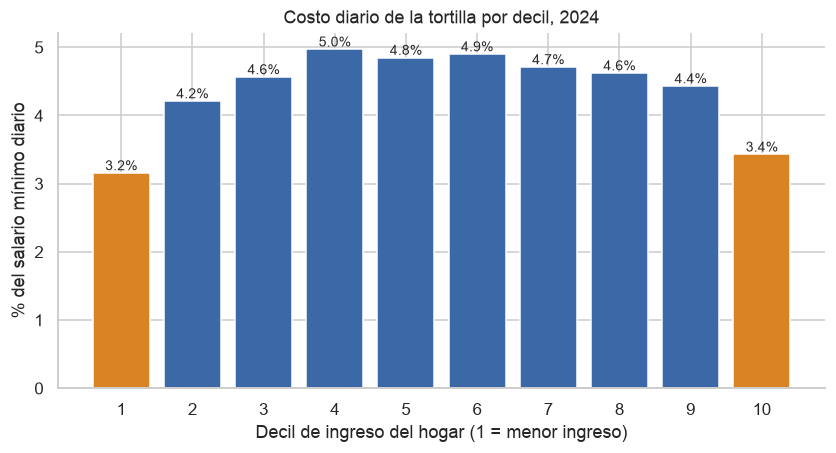

,anio,decil,kg_dia_hogar,precio_kg,salario_diario,costo_tortilla_dia_hogar,pct_salario,pct_salario_enigh
0,2024,1,0.33,24.0,248.93,7.85,3.15,2.91
1,2024,2,0.44,24.0,248.93,10.48,4.21,3.87
2,2024,3,0.47,24.0,248.93,11.36,4.56,4.22
3,2024,4,0.52,24.0,248.93,12.37,4.97,4.57
4,2024,5,0.50,24.0,248.93,12.07,4.85,4.54
5,2024,6,0.51,24.0,248.93,12.19,4.90,4.66
6,2024,7,0.49,24.0,248.93,11.72,4.71,4.50
7,2024,8,0.48,24.0,248.93,11.50,4.62,4.46
8,2024,9,0.46,24.0,248.93,11.03,4.43,4.29
9,2024,10,0.36,24.0,248.93,8.53,3.43,3.38


In [8]:
dec = pct_salario_por_decil(salario, precio, enigh)
ANIO_DEC = int(dec.anio.iloc[0])
fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.bar(dec.decil, dec.pct_salario, color=[C_ZLFN if d in (1, 10) else C_GEN for d in dec.decil])
ax.bar_label(barras, fmt="%.1f%%", fontsize=9)
ax.set_xticks(dec.decil)
ax.set_xlabel("Decil de ingreso del hogar (1 = menor ingreso)")
ax.set_ylabel("% del salario mínimo diario")
ax.set_title(f"Costo diario de la tortilla por decil, {ANIO_DEC}")
guardar(fig, "decil")
plt.show()
display(dec.round(2))

Un salario mínimo no es el ingreso del hogar. Para medir la carga relativa al ingreso se divide el gasto diario en tortilla (ENIGH) entre el ingreso corriente diario del hogar (`ing_cor` trimestral entre 90), promedio ponderado por decil.

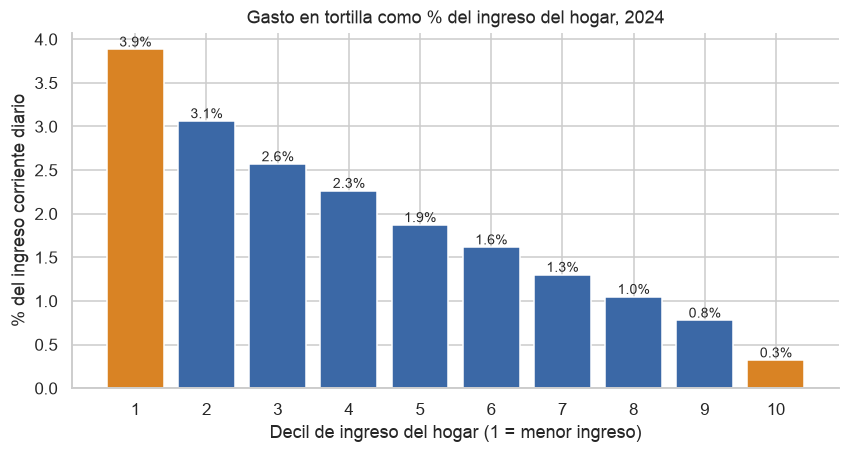

,decil,ingreso_dia_hogar,pct_salario_enigh,pct_ingreso
0,1,186.61,2.91,3.88
1,2,314.41,3.87,3.06
2,3,409.38,4.22,2.57
3,4,502.71,4.57,2.26
4,5,603.41,4.54,1.87
5,6,717.76,4.66,1.62
6,7,860.55,4.50,1.30
7,8,1058.77,4.46,1.05
8,9,1374.55,4.29,0.78
9,10,2623.24,3.38,0.32


In [9]:
hog = pd.read_parquet(raiz / "data" / "interim" / "ENIGH" / f"tortilla_hogar_{ANIO_DEC}.parquet").sort_values("ing_cor")
hog["decil"] = np.ceil(hog.factor.cumsum() / hog.factor.sum() * 10 - 1e-9).clip(1, 10).astype(int)
ing = hog.groupby("decil").apply(lambda x: np.average(x.ing_cor, weights=x.factor) / 90, include_groups=False).rename("ingreso_dia_hogar")
dec = dec.merge(ing, left_on="decil", right_index=True)
dec["pct_ingreso"] = dec.pct_salario_enigh * dec.salario_diario / dec.ingreso_dia_hogar
fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.bar(dec.decil, dec.pct_ingreso, color=[C_ZLFN if d in (1, 10) else C_GEN for d in dec.decil])
ax.bar_label(barras, fmt="%.1f%%", fontsize=9)
ax.set_xticks(dec.decil)
ax.set_xlabel("Decil de ingreso del hogar (1 = menor ingreso)")
ax.set_ylabel("% del ingreso corriente diario")
ax.set_title(f"Gasto en tortilla como % del ingreso del hogar, {ANIO_DEC}")
guardar(fig, "decil_ingreso")
plt.show()
dec[["decil", "ingreso_dia_hogar", "pct_salario_enigh", "pct_ingreso"]].round(2)

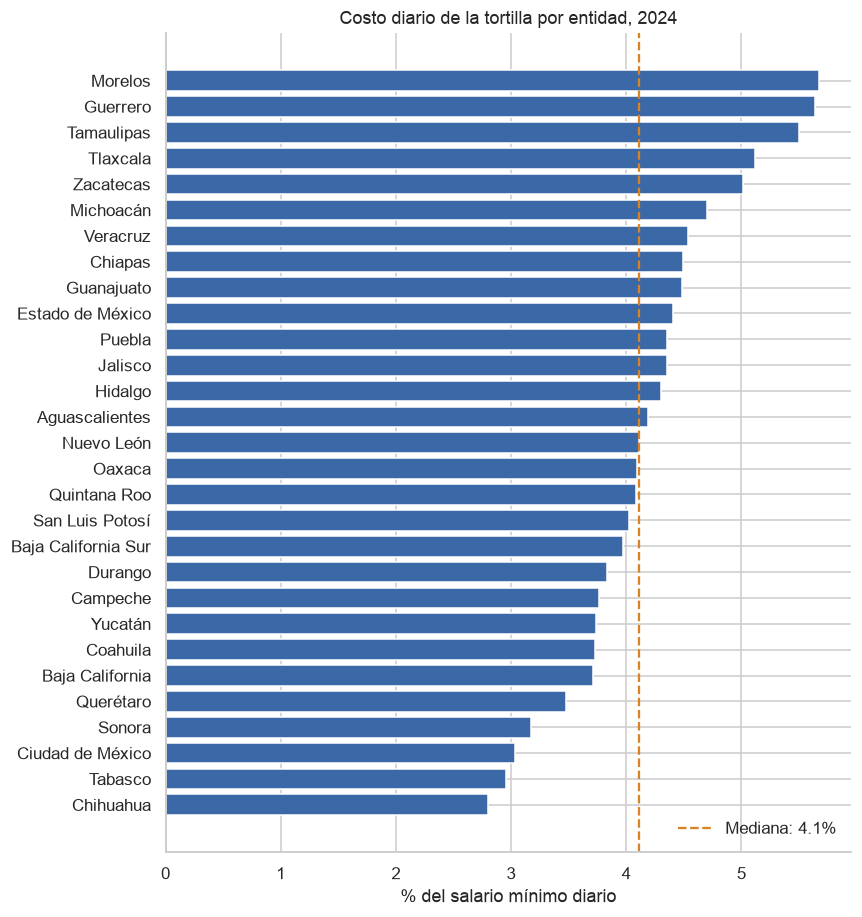

29 de 32 entidades tienen precio PROFECO en 2024; sin precio: Colima, Nayarit, Sinaloa. Mayor carga: Morelos (5.7%); menor: Chihuahua (2.8%).

In [10]:
ent = pct_salario_por_entidad(salario, precio, enigh)
sin_precio = ent[ent.pct_salario.isna()].estado.tolist()
ent = ent.dropna(subset=["pct_salario"]).sort_values("pct_salario")
mediana_ent = ent.pct_salario.median()
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(ent.estado, ent.pct_salario, color=C_GEN)
ax.axvline(mediana_ent, color=C_ZLFN, ls="--", lw=1.5, label=f"Mediana: {mediana_ent:.1f}%")
ax.set_xlabel("% del salario mínimo diario")
ax.set_title(f"Costo diario de la tortilla por entidad, {ANIO_DEC}")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
guardar(fig, "entidad")
plt.show()
display(Markdown(
    f"{len(ent)} de 32 entidades tienen precio PROFECO en {ANIO_DEC}; sin precio: {', '.join(sin_precio) if sin_precio else 'ninguna'}. "
    f"Mayor carga: {ent.iloc[-1].estado} ({ent.iloc[-1].pct_salario:.1f}%); menor: {ent.iloc[0].estado} ({ent.iloc[0].pct_salario:.1f}%)."
))

## 6 | Transmisión del maíz a la tortilla

Se compara el maíz blanco mayorista SNIIM (promedio nacional de los cinco mercados) con el precio nacional de la tortilla en tortillería. Las variaciones solo se calculan entre meses consecutivos con precio PROFECO, y el rezago de maíz siempre tiene dato.

Mercados con precio por mes: mínimo 5, máximo 5. Meses con ambos precios: 84 de 156. Variaciones mensuales con dato en la tortilla: 74; interanuales: 68.

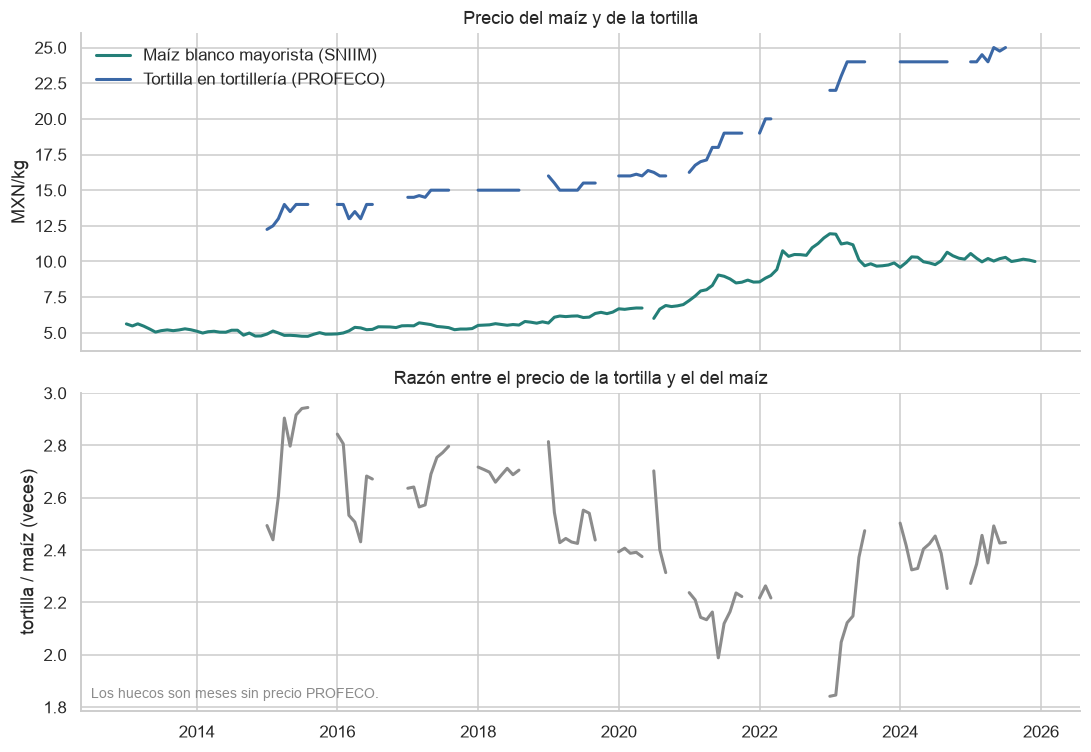

In [11]:
maiz_mercado = sniim.groupby(["fecha", "mercado"]).precio_mxn_kg.mean()
maiz = maiz_mercado.groupby("fecha").mean().reindex(CALENDARIO).rename("maiz")
n_mercados = maiz_mercado.groupby("fecha").size().reindex(CALENDARIO)
tort = M.precio_kg.reindex(CALENDARIO).rename("tortilla")
ratio = (tort / maiz).rename("razon")

d_t, d_m = tort.pct_change(fill_method=None) * 100, maiz.pct_change(fill_method=None) * 100
y_t, y_m = tort.pct_change(12, fill_method=None) * 100, maiz.pct_change(12, fill_method=None) * 100

display(Markdown(
    f"Mercados con precio por mes: mínimo {int(n_mercados.min())}, máximo {int(n_mercados.max())}. "
    f"Meses con ambos precios: {int(pd.concat([tort, maiz], axis=1).dropna().shape[0])} de {len(CALENDARIO)}. "
    f"Variaciones mensuales con dato en la tortilla: {int(d_t.notna().sum())}; interanuales: {int(y_t.notna().sum())}."
))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(maiz.index, maiz, color=C_MAIZ, lw=2, label="Maíz blanco mayorista (SNIIM)")
axes[0].plot(tort.index, tort, color=C_GEN, lw=2, label="Tortilla en tortillería (PROFECO)")
axes[0].set_ylabel("MXN/kg")
axes[0].set_title("Precio del maíz y de la tortilla")
axes[0].legend(frameon=False)
axes[1].plot(ratio.index, ratio, color=C_GRIS, lw=2)
axes[1].set_ylabel("tortilla / maíz (veces)")
axes[1].set_title("Razón entre el precio de la tortilla y el del maíz")
axes[1].text(0.01, 0.04, "Los huecos son meses sin precio PROFECO.", transform=axes[1].transAxes, fontsize=9, color=C_GRIS)
fig.tight_layout()
guardar(fig, "maiz_tortilla")
plt.show()

In [12]:
rz = ratio.dropna()
rz_anual = rz.groupby(rz.index.year).mean()
display(Markdown(
    f"La razón tortilla/maíz promedia {rz_anual.iloc[0]:.2f} en {rz_anual.index[0]} y {rz_anual.iloc[-1]:.2f} en {rz_anual.index[-1]}; "
    f"su mínimo anual es {rz_anual.min():.2f} ({rz_anual.idxmin()}) y su máximo {rz_anual.max():.2f} ({rz_anual.idxmax()})."
))
display(rz_anual.round(2).to_frame("razon tortilla/maiz").T)

La razón tortilla/maíz promedia 2.76 en 2015 y 2.40 en 2025; su mínimo anual es 2.12 (2023) y su máximo 2.76 (2015).

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
razon tortilla/maiz,2.76,2.64,2.68,2.7,2.51,2.42,2.16,2.23,2.12,2.39,2.4


variación mensual                  variación interanual                 
                       n pearson spearman                    n pearson spearman
rezago                                                                         
0                     72   -0.20    -0.16                   66    0.46     0.30
1                     72    0.00     0.08                   66    0.53     0.41
2                     72    0.24     0.23                   66    0.59     0.50
3                     73    0.05     0.10                   66    0.59     0.53
4                     74    0.16     0.15                   68    0.61     0.58
5                     74   -0.04    -0.02                   68    0.57     0.55
6                     74    0.05     0.10                   68    0.54     0.53
7                     73   -0.26    -0.17                   66    0.53     0.46
8                     72    0.25     0.19                   66    0.55     0.51
9                     72    0.13     0.05                   66    0.58     0.59
10                    72    0.10     0.05                   67    0.60     0.64
11                    72    0.29     0.21                   67    0.58     0.65
12                    72    0.05     0.08                   67    0.44     0.55

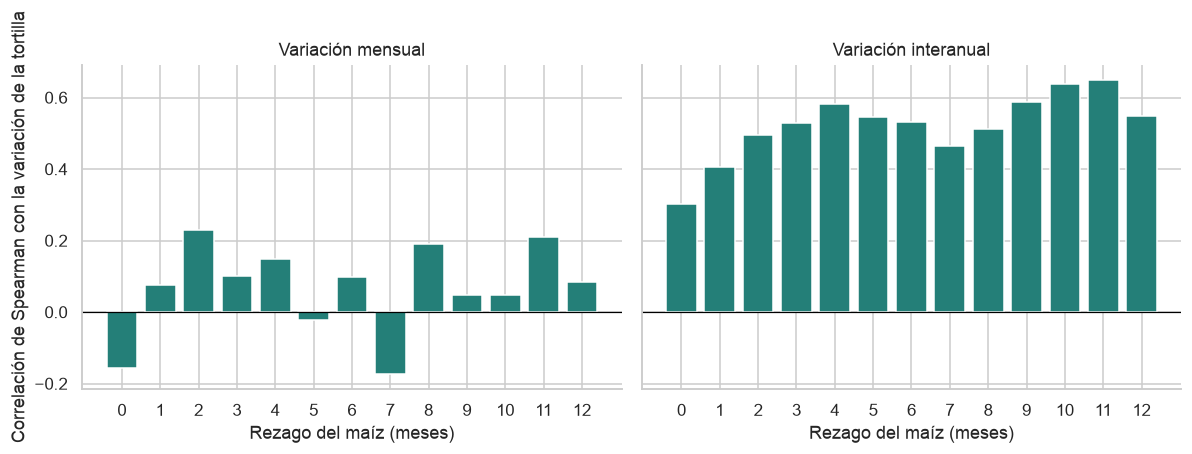

Variación mensual: Spearman en rezago 0 de -0.16; máximo de 0.23 en rezago 2 (n = 72). Variación interanual: rezago 0 de 0.30; entre rezagos 2 y 12, de 0.46 a 0.65; el máximo (0.65) cae en el rezago 11 (n = 67). Las variaciones interanuales consecutivas se traslapan, por lo que el número efectivo de observaciones es menor.

In [13]:
def correlaciones(y, x, rezagos=range(0, 13)):
    filas = []
    for k in rezagos:
        par = pd.concat([y, x.shift(k)], axis=1).dropna()
        filas.append({
            "rezago": k, "n": len(par),
            "pearson": par.corr().iloc[0, 1],
            "spearman": par.corr(method="spearman").iloc[0, 1],
        })
    return pd.DataFrame(filas).set_index("rezago")

cc_mes = correlaciones(d_t, d_m)
cc_anio = correlaciones(y_t, y_m)
display(pd.concat({"variación mensual": cc_mes, "variación interanual": cc_anio}, axis=1).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cc, titulo in [(axes[0], cc_mes, "Variación mensual"), (axes[1], cc_anio, "Variación interanual")]:
    ax.bar(cc.index, cc.spearman, color=C_MAIZ)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("Rezago del maíz (meses)")
    ax.set_xticks(range(0, 13))
axes[0].set_ylabel("Correlación de Spearman con la variación de la tortilla")
fig.tight_layout()
guardar(fig, "rezagos")
plt.show()

mejor_m, mejor_a = cc_mes.spearman.idxmax(), cc_anio.spearman.idxmax()
display(Markdown(
    f"Variación mensual: Spearman en rezago 0 de {cc_mes.spearman[0]:.2f}; máximo de {cc_mes.spearman.max():.2f} en rezago {mejor_m} (n = {int(cc_mes.n[mejor_m])}). "
    f"Variación interanual: rezago 0 de {cc_anio.spearman[0]:.2f}; entre rezagos 2 y 12, de {cc_anio.spearman[2:].min():.2f} a {cc_anio.spearman[2:].max():.2f}; el máximo ({cc_anio.spearman.max():.2f}) cae en el rezago {mejor_a} (n = {int(cc_anio.n[mejor_a])}). Las variaciones interanuales consecutivas se traslapan, por lo que el número efectivo de observaciones es menor."
))

### Episodio 2022: el pico del maíz

PROFECO solo tiene enero–marzo de 2022. Para comparar años con los mismos meses se usa el promedio de enero a marzo, que existe en todos los años de 2015 a 2025.

In [14]:
base = pd.concat([maiz, tort], axis=1)
q1 = base[base.index.month <= 3].dropna()
q1 = q1.groupby(q1.index.year).agg(["mean", "size"])
q1 = pd.DataFrame({
    "maiz": q1[("maiz", "mean")], "tortilla": q1[("tortilla", "mean")], "meses": q1[("tortilla", "size")],
})
q1["razon"] = q1.tortilla / q1.maiz
q1["maiz_var_anual_pct"] = q1.maiz.pct_change() * 100
q1["tortilla_var_anual_pct"] = q1.tortilla.pct_change() * 100
display(q1.round(2))

pico = maiz["2021-01-01":"2023-12-01"].idxmax()
maiz_2020 = maiz["2020-01-01":"2020-12-01"].mean()
tort_ant = M.precio_kg[M.index.year == 2021].mean()
tort_2023 = M.precio_kg[M.index.year == 2023].mean()
fila = lambda a: q1.loc[a]
display(Markdown(
    f"El maíz mayorista alcanza su máximo de 2021–2023 en {pico:%Y-%m} ({maiz[pico]:.2f} MXN/kg), "
    f"{(maiz[pico] / maiz_2020 - 1) * 100:.0f}% sobre su promedio de 2020. "
    f"Entre el trimestre enero–marzo de 2021 y el de 2023 el maíz sube {(fila(2023).maiz / fila(2021).maiz - 1) * 100:.0f}% "
    f"y la tortilla {(fila(2023).tortilla / fila(2021).tortilla - 1) * 100:.0f}%; "
    f"la razón tortilla/maíz pasa de {fila(2021).razon:.2f} a {fila(2023).razon:.2f}. "
    f"De enero–marzo de 2021 a 2022 el maíz sube {fila(2022).maiz_var_anual_pct:.0f}% y la tortilla {fila(2022).tortilla_var_anual_pct:.0f}%."
))

,maiz,tortilla,meses,razon,maiz_var_anual_pct,tortilla_var_anual_pct
2015,5.01,12.58,3,2.51,NaN,NaN
2016,5.01,13.67,3,2.73,0.13,8.61
2017,5.56,14.54,3,2.61,10.93,6.39
2018,5.54,15.00,3,2.71,-0.42,3.16
2019,5.98,15.50,3,2.59,8.03,3.33
2020,6.68,16.00,3,2.40,11.56,3.23
2021,7.59,16.67,3,2.20,13.70,4.17
2022,8.81,19.67,3,2.23,16.02,18.00
2023,11.70,22.33,3,1.91,32.80,13.56
2024,9.95,24.00,3,2.41,-14.97,7.46


El maíz mayorista alcanza su máximo de 2021–2023 en 2023-01 (11.95 MXN/kg), 78% sobre su promedio de 2020. Entre el trimestre enero–marzo de 2021 y el de 2023 el maíz sube 54% y la tortilla 34%; la razón tortilla/maíz pasa de 2.20 a 1.91. De enero–marzo de 2021 a 2022 el maíz sube 16% y la tortilla 18%.

## 7 | Tortilla y Gruma

Se compara el precio anual de la tortilla con el rendimiento acumulado de Gruma. Con diez observaciones anuales el análisis es descriptivo.

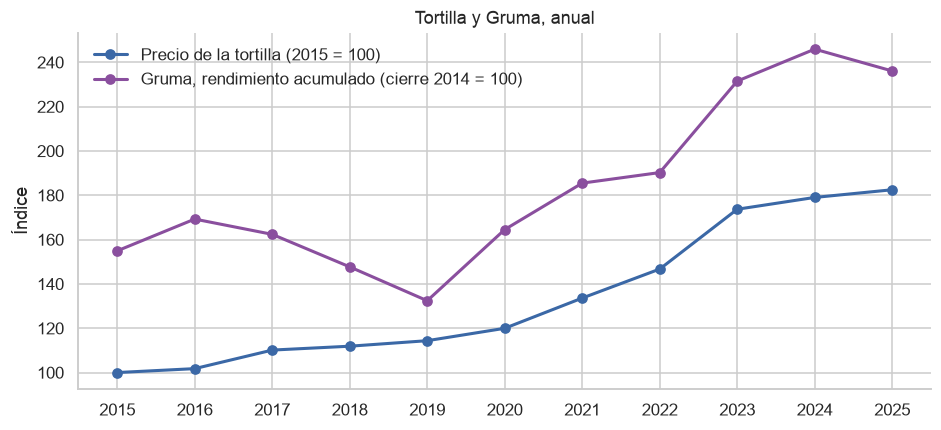

,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
tortilla_var_pct,1.8,8.2,1.6,2.2,4.9,11.4,9.8,18.4,3.1,1.9
gruma_rend_pct,9.3,-4.1,-9.0,-10.3,24.3,12.7,2.6,21.7,6.2,-4.0


Spearman entre niveles anuales: 0.80 (n = 11); entre variaciones anuales: 0.52 (n = 10). Los niveles comparten tendencia creciente, por lo que su correlación es alta casi por construcción; la de variaciones es la medida relevante y se apoya en pocos años. Gruma acumula 136% entre el cierre de 2014 y 2025; la tortilla 82% entre 2015 y 2025.

In [15]:
r_gr = rend["GRUMAB.MX"].copy()
r_gr.index = r_gr.index.to_period("M").to_timestamp()
r_gr = r_gr["2013-01-01":"2025-12-01"]
indice = (1 + r_gr).cumprod()
cierre_anual = indice.groupby(indice.index.year).last()
gruma_anual = (cierre_anual.pct_change() * 100)
gruma_anual.iloc[0] = (cierre_anual.iloc[0] - 1) * 100

ref = 2014
t_idx = G.precio_kg / G.precio_kg.loc[2015] * 100
g_idx = cierre_anual / cierre_anual.loc[2014] * 100
g_idx = g_idx.loc[2015:]
t_idx = t_idx.loc[2015:]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t_idx.index, t_idx, color=C_GEN, lw=2, marker="o", label="Precio de la tortilla (2015 = 100)")
ax.plot(g_idx.index, g_idx, color=C_GRUMA, lw=2, marker="o", label="Gruma, rendimiento acumulado (cierre 2014 = 100)")
ax.set_xticks(range(2015, 2026))
ax.set_ylabel("Índice")
ax.set_title("Tortilla y Gruma, anual")
ax.legend(frameon=False)
guardar(fig, "gruma")
plt.show()

comp = pd.DataFrame({
    "tortilla_var_pct": G.precio_kg.pct_change() * 100,
    "gruma_rend_pct": gruma_anual,
}).loc[2016:]
comp_niveles = pd.concat([t_idx.rename("tortilla"), g_idx.rename("gruma")], axis=1)
rho_n = comp_niveles.corr(method="spearman").iloc[0, 1]
rho_v = comp.corr(method="spearman").iloc[0, 1]
display(comp.round(1).T)
display(Markdown(
    f"Spearman entre niveles anuales: {rho_n:.2f} (n = {len(comp_niveles)}); entre variaciones anuales: {rho_v:.2f} (n = {len(comp)}). "
    f"Los niveles comparten tendencia creciente, por lo que su correlación es alta casi por construcción; "
    f"la de variaciones es la medida relevante y se apoya en pocos años. "
    f"Gruma acumula {g_idx.iloc[-1] - 100:.0f}% entre el cierre de 2014 y 2025; la tortilla {t_idx.iloc[-1] - 100:.0f}% entre 2015 y 2025."
))

## 8 | Síntesis

In [16]:
p15, p25 = G.loc[2015], G.loc[2025]
z19, z25 = Z.loc[2019], Z.loc[2025]
d1, d10 = dec.set_index("decil").loc[1], dec.set_index("decil").loc[10]
decmax = dec.loc[dec.pct_salario.idxmax()]

hallazgos = [
    f"**La tortilla pesa mucho menos en el salario mínimo.** El costo diario de la tortilla del hogar promedio pasa de {p15.pct_salario:.1f}% del salario mínimo general en 2015 a {p25.pct_salario:.1f}% en 2025. "
    f"La ENIGH directa da {G.loc[2014, 'pct_salario_enigh']:.1f}% en 2014 y {G.loc[2024, 'pct_salario_enigh']:.1f}% en 2024.",
    f"**El motivo es el salario, no el precio.** La tortilla pasa de {p15.precio_kg:.2f} a {p25.precio_kg:.2f} MXN/kg ({(p25.precio_kg / p15.precio_kg - 1) * 100:.0f}% más) "
    f"mientras el salario general pasa de {p15.salario_diario:.2f} a {p25.salario_diario:.2f} MXN/día ({(p25.salario_diario / p15.salario_diario - 1) * 100:.0f}% más); "
    f"el hogar promedio también compra menos: {p15.kg_dia_hogar:.2f} kg/día en 2015 y {p25.kg_dia_hogar:.2f} en 2025 (valores interpolados de la ENIGH).",
    f"**Trabajo por kilo.** Un kilo costaba {p15.minutos_trabajo_por_kg:.0f} minutos de trabajo a salario mínimo en 2015 y {p25.minutos_trabajo_por_kg:.0f} en 2025; "
    f"un salario compraba {p15.kg_por_salario:.1f} kg y ahora compra {p25.kg_por_salario:.1f} kg.",
    f"**La frontera lo vive distinto.** Con el salario de la ZLFN el porcentaje es {z19.pct_salario:.1f}% en 2019 y {z25.pct_salario:.1f}% en 2025, frente a {G.loc[2019, 'pct_salario']:.1f}% y {p25.pct_salario:.1f}% con el salario general.",
    f"**Desigualdad.** En {ANIO_DEC} el hogar del decil 1 gasta {d1.pct_salario:.1f}% de un salario mínimo diario en tortilla y el del decil 10 {d10.pct_salario:.1f}%: en términos de un salario las cargas son parecidas (máximo en el decil {int(decmax.decil)}, {decmax.pct_salario:.1f}%). "
    f"Medida contra el ingreso del hogar, la tortilla es {d1.pct_ingreso:.1f}% del ingreso del decil 1 y {d10.pct_ingreso:.1f}% del decil 10, {d1.pct_ingreso / d10.pct_ingreso:.0f} veces más. "
    f"Entre entidades va de {ent.iloc[0].pct_salario:.1f}% ({ent.iloc[0].estado}) a {ent.iloc[-1].pct_salario:.1f}% ({ent.iloc[-1].estado}).",
    f"**Transmisión del maíz.** La razón tortilla/maíz pasa de {rz_anual.iloc[0]:.2f} en {rz_anual.index[0]} a {rz_anual.iloc[-1]:.2f} en {rz_anual.index[-1]}. "
    f"Entre enero–marzo de 2021 y 2023 el maíz sube {(fila(2023).maiz / fila(2021).maiz - 1) * 100:.0f}% y la tortilla {(fila(2023).tortilla / fila(2021).tortilla - 1) * 100:.0f}%. "
    f"Entre variaciones mensuales la correlación de Spearman es {cc_mes.spearman[0]:.2f} sin rezago y no supera {cc_mes.spearman.max():.2f} con ningún rezago de 0 a 12 meses; "
    f"entre variaciones interanuales es {cc_anio.spearman[0]:.2f} sin rezago y oscila entre {cc_anio.spearman[2:].min():.2f} y {cc_anio.spearman[2:].max():.2f} en rezagos de 2 a 12 meses, sin un rezago único dominante.",
    f"**Gruma.** La correlación de Spearman entre las variaciones anuales de la tortilla y el rendimiento anual de Gruma es {rho_v:.2f} (n = {len(comp)}); "
    f"con tan pocas observaciones no es concluyente. Los niveles suben juntos ({rho_n:.2f}), en parte por tendencia común.",
]
display(Markdown("\n\n".join(f"{i}. {h}" for i, h in enumerate(hallazgos, 1))))

1. **La tortilla pesa mucho menos en el salario mínimo.** El costo diario de la tortilla del hogar promedio pasa de 10.6% del salario mínimo general en 2015 a 4.0% en 2025. La ENIGH directa da 10.1% en 2014 y 4.1% en 2024.

2. **El motivo es el salario, no el precio.** La tortilla pasa de 13.41 a 24.46 MXN/kg (82% más) mientras el salario general pasa de 67.59 a 278.80 MXN/día (312% más); el hogar promedio también compra menos: 0.54 kg/día en 2015 y 0.45 en 2025 (valores interpolados de la ENIGH).

3. **Trabajo por kilo.** Un kilo costaba 95 minutos de trabajo a salario mínimo en 2015 y 42 en 2025; un salario compraba 5.0 kg y ahora compra 11.4 kg.

4. **La frontera lo vive distinto.** Con el salario de la ZLFN el porcentaje es 4.5% en 2019 y 2.6% en 2025, frente a 7.7% y 4.0% con el salario general.

5. **Desigualdad.** En 2024 el hogar del decil 1 gasta 3.2% de un salario mínimo diario en tortilla y el del decil 10 3.4%: en términos de un salario las cargas son parecidas (máximo en el decil 4, 5.0%). Medida contra el ingreso del hogar, la tortilla es 3.9% del ingreso del decil 1 y 0.3% del decil 10, 12 veces más. Entre entidades va de 2.8% (Chihuahua) a 5.7% (Morelos).

6. **Transmisión del maíz.** La razón tortilla/maíz pasa de 2.76 en 2015 a 2.40 en 2025. Entre enero–marzo de 2021 y 2023 el maíz sube 54% y la tortilla 34%. Entre variaciones mensuales la correlación de Spearman es -0.16 sin rezago y no supera 0.23 con ningún rezago de 0 a 12 meses; entre variaciones interanuales es 0.30 sin rezago y oscila entre 0.46 y 0.65 en rezagos de 2 a 12 meses, sin un rezago único dominante.

7. **Gruma.** La correlación de Spearman entre las variaciones anuales de la tortilla y el rendimiento anual de Gruma es 0.52 (n = 10); con tan pocas observaciones no es concluyente. Los niveles suben juntos (0.80), en parte por tendencia común.

### Cifras titular

In [17]:
titulares = pd.DataFrame({
    "cifra": [
        "% del salario mínimo general que se come la tortilla",
        "Minutos de trabajo por kg de tortilla",
        f"% del ingreso del hogar en tortilla, decil 1 vs decil 10 ({ANIO_DEC})",
    ],
    "antes": [f"{p15.pct_salario:.1f}% (2015)", f"{p15.minutos_trabajo_por_kg:.0f} min (2015)", f"{d1.pct_ingreso:.1f}% (decil 1)"],
    "ahora": [f"{p25.pct_salario:.1f}% (2025)", f"{p25.minutos_trabajo_por_kg:.0f} min (2025)", f"{d10.pct_ingreso:.1f}% (decil 10)"],
})
display(titulares.style.hide(axis="index"))

cifra,antes,ahora
% del salario mínimo general que se come la tortilla,10.6% (2015),4.0% (2025)
Minutos de trabajo por kg de tortilla,95 min (2015),42 min (2025)
"% del ingreso del hogar en tortilla, decil 1 vs decil 10 (2024)",3.9% (decil 1),0.3% (decil 10)


**Limitaciones.** Los consumos mensuales son interpolaciones entre encuestas bienales; PROFECO tiene entre 3 y 10 meses por año; la ZLFN usa precio y consumo nacionales; y los precios no están deflactados. Las asociaciones con maíz y Gruma no prueban causalidad.